In [ ]:
# Revision

# "A layer takes 3 neurons in, feeding 5 neurons in the next layer. What's the shape of that weight matrix?"

# "Two paths in the computation graph both lead back to the same weight. How do you combine their gradients?"

# "Sigmoid and tanh are the usual suspects behind vanishing gradients. Why?"

# "Can a neural network do regression?"

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

In [ ]:
!wget "https://drive.google.com/uc?export=download&id=1GVhrh2rH6hUunV4Tf7lQoSFsqov9aPjU" -O healthyfime.csv
df = pd.read_csv("healthyfime.csv")
df.head()

--2026-10-01 15:51:00--  https://drive.google.com/uc?export=download&id=1GVhrh2rH6hUunV4Tf7lQoSFsqov9aPjU
Resolving drive.google.com (drive.google.com)... 142.251.165.102, 142.251.165.113, 142.251.165.138, ...
Connecting to drive.google.com (drive.google.com)|142.251.165.102|:443... connected.
HTTP request sent, awaiting response... 303 See Other
Location: https://drive.usercontent.google.com/download?id=1GVhrh2rH6hUunV4Tf7lQoSFsqov9aPjU&export=download [following]
--2026-10-01 15:51:00--  https://drive.usercontent.google.com/download?id=1GVhrh2rH6hUunV4Tf7lQoSFsqov9aPjU&export=download
Resolving drive.usercontent.google.com (drive.usercontent.google.com)... 142.250.111.132, 2607:f8b0:4023:1425::84
Connecting to drive.usercontent.google.com (drive.usercontent.google.com)|142.250.111.132|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 761835 (744K) [application/octet-stream]
Saving to: ‘healthyfime.csv’

healthyfime.csv     100%[===================>] 743.98K  -

,age,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class
0,27.0,M,172.3,75.24,21.3,80.0,130.0,54.9,18.4,60.0,217.0,C
1,25.0,M,165.0,55.80,15.7,77.0,126.0,36.4,16.3,53.0,229.0,A
2,31.0,M,179.6,78.00,20.1,92.0,152.0,44.8,12.0,49.0,181.0,C
3,32.0,M,174.5,71.10,18.4,76.0,147.0,41.4,15.2,53.0,219.0,B
4,28.0,M,173.8,67.70,17.1,70.0,127.0,43.5,27.1,45.0,217.0,B


In [ ]:
df["class"].unique()

array(['C', 'A', 'B', 'D'], dtype=object)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13393 entries, 0 to 13392
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      13393 non-null  float64
 1   gender                   13393 non-null  object 
 2   height_cm                13393 non-null  float64
 3   weight_kg                13393 non-null  float64
 4   body fat_%               13393 non-null  float64
 5   diastolic                13393 non-null  float64
 6   systolic                 13393 non-null  float64
 7   gripForce                13393 non-null  float64
 8   sit and bend forward_cm  13393 non-null  float64
 9   sit-ups counts           13393 non-null  float64
 10  broad jump_cm            13393 non-null  float64
 11  class                    13393 non-null  object 
dtypes: float64(10), object(2)
memory usage: 1.2+ MB


In [ ]:
# Quiz 1 -
# c. At least one feature (gender) is stored as a non-numerical (object) dtype.

In [ ]:
df.gender.unique()

array(['M', 'F'], dtype=object)

In [ ]:
df.replace({"M": 0, "F": 1}, inplace=True)
df.head()

/tmp/ipykernel_676/3197794122.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.replace({"M": 0, "F": 1}, inplace=True)


,age,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class
0,27.0,0,172.3,75.24,21.3,80.0,130.0,54.9,18.4,60.0,217.0,C
1,25.0,0,165.0,55.80,15.7,77.0,126.0,36.4,16.3,53.0,229.0,A
2,31.0,0,179.6,78.00,20.1,92.0,152.0,44.8,12.0,49.0,181.0,C
3,32.0,0,174.5,71.10,18.4,76.0,147.0,41.4,15.2,53.0,219.0,B
4,28.0,0,173.8,67.70,17.1,70.0,127.0,43.5,27.1,45.0,217.0,B


In [ ]:
classes = list(df['class'].unique())
mapping_dict = {ch: i for i, ch in enumerate(sorted(classes, reverse=True))}
print(mapping_dict)
df['class'].replace(mapping_dict, inplace=True)
df.head()

{'D': 0, 'C': 1, 'B': 2, 'A': 3}


/tmp/ipykernel_676/2550660351.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['class'].replace(mapping_dict, inplace=True)
/tmp/ipykernel_676/2550660351.py:4: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['class'].replace(mapping_dict, inplace=True)


,age,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class
0,27.0,0,172.3,75.24,21.3,80.0,130.0,54.9,18.4,60.0,217.0,1
1,25.0,0,165.0,55.80,15.7,77.0,126.0,36.4,16.3,53.0,229.0,3
2,31.0,0,179.6,78.00,20.1,92.0,152.0,44.8,12.0,49.0,181.0,1
3,32.0,0,174.5,71.10,18.4,76.0,147.0,41.4,15.2,53.0,219.0,2
4,28.0,0,173.8,67.70,17.1,70.0,127.0,43.5,27.1,45.0,217.0,2


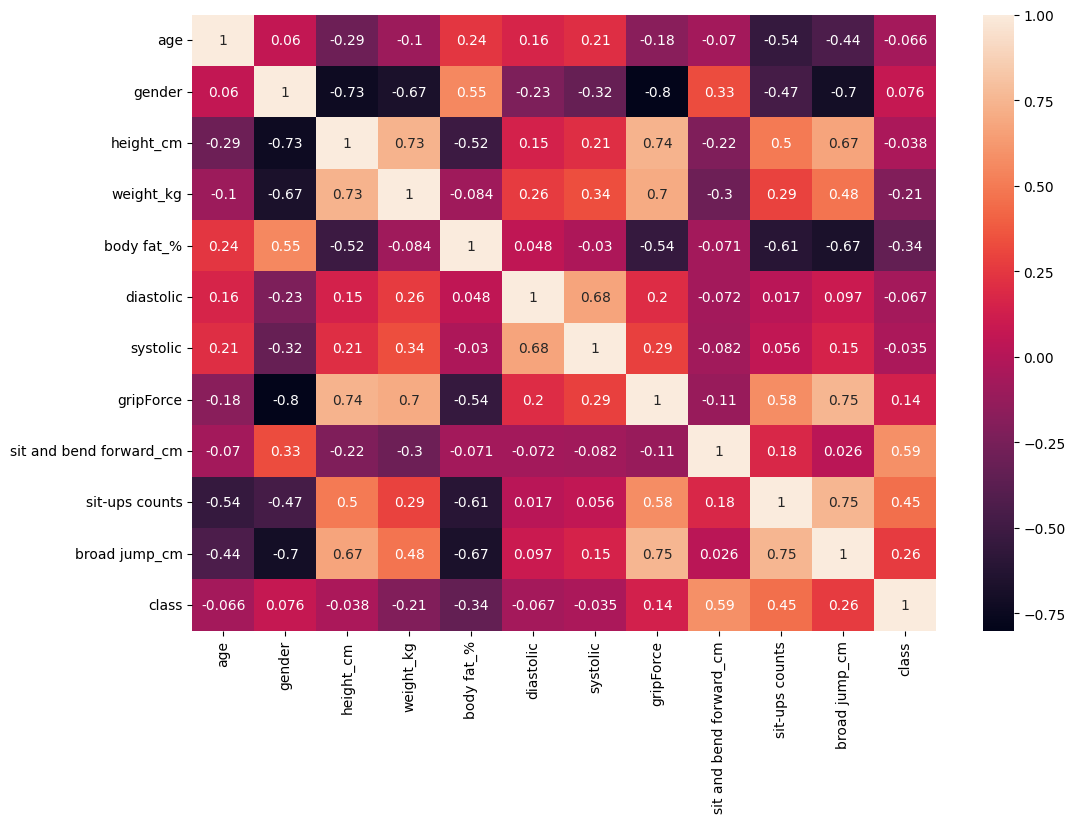

In [ ]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True)
plt.show()

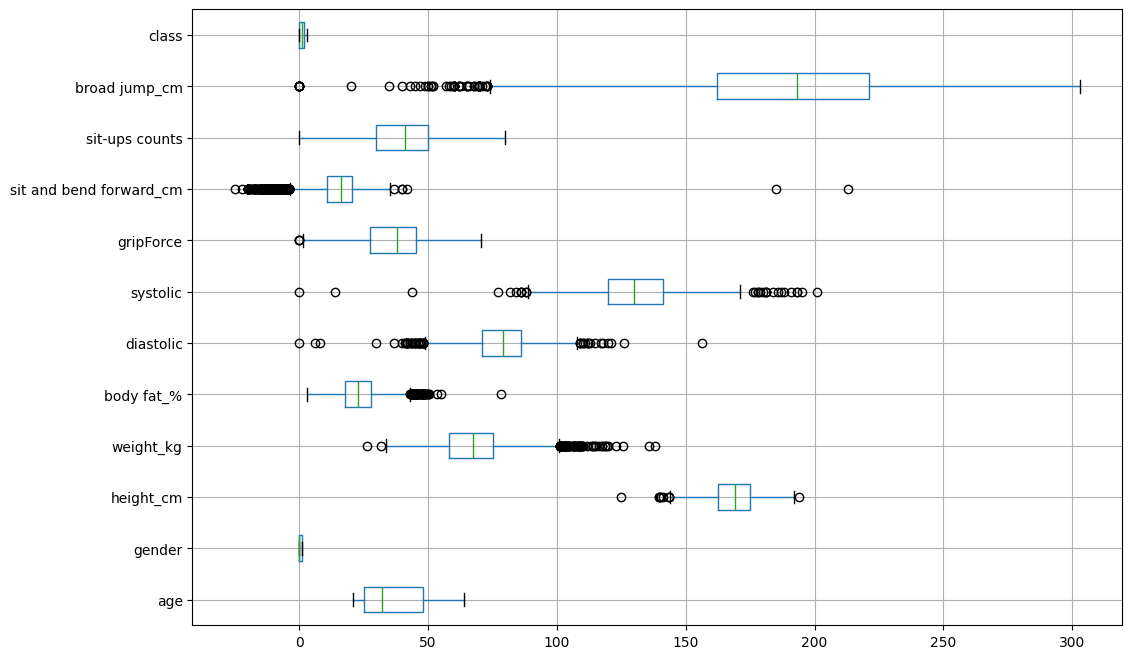

In [ ]:
df.boxplot(figsize=(12, 8), rot=0, vert=False)
plt.show()

In [ ]:
X, y = df.iloc[:, :-1], df.iloc[:, -1]
print(X.shape, y.shape)

(13393, 11) (13393,)


In [ ]:
X.head()

,age,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm
0,27.0,0,172.3,75.24,21.3,80.0,130.0,54.9,18.4,60.0,217.0
1,25.0,0,165.0,55.80,15.7,77.0,126.0,36.4,16.3,53.0,229.0
2,31.0,0,179.6,78.00,20.1,92.0,152.0,44.8,12.0,49.0,181.0
3,32.0,0,174.5,71.10,18.4,76.0,147.0,41.4,15.2,53.0,219.0
4,28.0,0,173.8,67.70,17.1,70.0,127.0,43.5,27.1,45.0,217.0


In [ ]:
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.1, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.1, random_state=42)

print('Train : ', X_train.shape, y_train.shape)
print('Valid : ', X_val.shape, y_val.shape)
print('Test  : ', X_test.shape, y_test.shape)

Train :  (10847, 11) (10847,)
Valid :  (1206, 11) (1206,)
Test  :  (1340, 11) (1340,)


In [ ]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [ ]:
import torch

print(torch.__version__)

2.11.0+cpu


In [ ]:
x = torch.tensor([1.0, 2.0, 3.0], requires_grad=True)  #### tell pytorch to track the operations so it can caluclate derivatives later
y = (x**2).sum() # [1, 4, 9]


In [ ]:
x

tensor([1., 2., 3.], requires_grad=True)

In [ ]:
print(x.requires_grad)

True


In [ ]:
y

tensor(14., grad_fn=<SumBackward0>)

In [ ]:
print(x.grad)

None


In [ ]:
y.backward() # derivative of y wrt x

In [ ]:
x.grad

tensor([2., 4., 6.])

# Create a NN using Pytorch

In [ ]:
import torch.nn as nn

layer = nn.Linear(in_features = 11, out_features = 64)

In [ ]:
print(layer.weight.shape)
print(layer.bias.shape)

torch.Size([64, 11])
torch.Size([64])


In [ ]:
model = nn.Sequential(
    nn.Linear(in_features = 11, out_features = 64),
    nn.ReLU(),
    nn.Linear(in_features = 64, out_features = 4)
)

In [ ]:
total_params = sum(p.numel() for p in model.parameters())
print(f"Total trainable parameters: {total_params}")

for name, param in model.named_parameters():
    print(name, tuple(param.shape))

Total trainable parameters: 1028
0.weight (64, 11)
0.bias (64,)
2.weight (4, 64)
2.bias (4,)


In [ ]:

# a. Early-training loss curves will differ slightly, since the initial weight distributions differ — but both should still learn.

In [ ]:
# LOM - Loss, Optimiser, Metric

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [ ]:
from torch.utils.data import TensorDataset, DataLoader

X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train.values, dtype=torch.long)
X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(y_val.values, dtype=torch.long)

train_ds = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_ds, batch_size=256, shuffle=True)

Combined Code

In [ ]:
def seed_everything(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)

seed_everything()

model = nn.Sequential(
    nn.Linear(11, 32),
    nn.ReLU(),
    nn.Linear(32, 16),
    nn.ReLU(),
    nn.Linear(16, 4)
)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

n_epochs = 500
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

for epoch in range(n_epochs):
    model.train()
    for xb, yb in train_loader:
        optimizer.zero_grad()
        preds = model(xb)
        loss = criterion(preds, yb)
        loss.backward()
        optimizer.step()

    # end-of-epoch bookkeeping — this is where "history" comes from
    model.eval()
    with torch.no_grad():
        train_preds = model(X_train_t)
        train_loss = criterion(train_preds, y_train_t).item()
        train_acc = (train_preds.argmax(1) == y_train_t).float().mean().item()

        val_preds = model(X_val_t)
        val_loss = criterion(val_preds, y_val_t).item()
        val_acc = (val_preds.argmax(1) == y_val_t).float().mean().item()

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    if epoch % 50 == 0:
        print(f"Epoch {epoch:03d} - loss: {train_loss:.4f} - acc: {train_acc:.4f} "
              f"- val_loss: {val_loss:.4f} - val_acc: {val_acc:.4f}")

Epoch 000 - loss: 1.2461 - acc: 0.4406 - val_loss: 1.2376 - val_acc: 0.4420
Epoch 050 - loss: 0.6270 - acc: 0.7447 - val_loss: 0.6129 - val_acc: 0.7546
Epoch 100 - loss: 0.5902 - acc: 0.7560 - val_loss: 0.5965 - val_acc: 0.7595
Epoch 150 - loss: 0.5738 - acc: 0.7661 - val_loss: 0.5878 - val_acc: 0.7546
Epoch 200 - loss: 0.5616 - acc: 0.7704 - val_loss: 0.5884 - val_acc: 0.7479
Epoch 250 - loss: 0.5521 - acc: 0.7751 - val_loss: 0.5899 - val_acc: 0.7579
Epoch 300 - loss: 0.5452 - acc: 0.7781 - val_loss: 0.5835 - val_acc: 0.7587
Epoch 350 - loss: 0.5378 - acc: 0.7823 - val_loss: 0.5846 - val_acc: 0.7570
Epoch 400 - loss: 0.5326 - acc: 0.7859 - val_loss: 0.5856 - val_acc: 0.7612
Epoch 450 - loss: 0.5288 - acc: 0.7868 - val_loss: 0.5889 - val_acc: 0.7604


In [ ]:
# Quiz 5
#
# c. Gradients will accumulate (sum up) across batches instead of being replaced, causing unstable or increasingly large parameter updates.